# 02 — EDA Mendalam: Dataset INDOMEME

**Proyek:** IndoMeme-XAI — Hate Speech Detection pada Meme Indonesia  
**Tujuan notebook ini:** Eksplorasi data menyeluruh sebelum modelling — memahami karakteristik dataset yang akan memengaruhi keputusan arsitektur dan training.

### Agenda EDA
1. Load data & gambaran umum
2. Distribusi label (hate & appropriate) — class imbalance
3. Analisis topik — distribusi dan korelasi dengan label hate
4. Analisis teks (OCR) — panjang, kosakata, missing, kualitas
5. Analisis caption — panjang, overlap dengan OCR
6. Analisis gambar — ukuran, rasio aspek, mode warna
7. Analisis topic × hate — korelasi silang (kritis untuk pipeline)
8. Temuan kritis dan implikasi untuk pipeline

---

## 1. Setup & Load Data

In [15]:
import os
import re
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
from pathlib import Path
from collections import Counter
from PIL import Image
from tqdm.auto import tqdm

warnings.filterwarnings('ignore')

# ============================================================
# SESUAIKAN: path root project Anda
# ============================================================
PROJECT_ROOT = Path(".").resolve().parent  # asumsi notebook ada di notebooks/
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
IMAGES_ROOT   = PROJECT_ROOT / "data" / "images"
FIGURES_DIR   = PROJECT_ROOT / "outputs" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Style
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")
COLORS = {'hate': '#E74C3C', 'not hate': '#3498DB',
          'inappropriate': '#E67E22', 'appropriate': '#27AE60'}

print(f"Project root: {PROJECT_ROOT}")
print("✅ Setup selesai.")

Project root: D:\PROYEK ML DAN AI\IndoMeme-XAI
✅ Setup selesai.


In [16]:
# Load data
df_train = pd.read_csv(PROCESSED_DIR / "train.csv")
df_val   = pd.read_csv(PROCESSED_DIR / "validation.csv")
df_test  = pd.read_csv(PROCESSED_DIR / "test.csv")
df_all   = pd.read_csv(PROCESSED_DIR / "all_splits.csv")

print("Dataset berhasil dimuat:")
print(f"  Train      : {len(df_train):,} sampel")
print(f"  Validation : {len(df_val):,} sampel")
print(f"  Test       : {len(df_test):,} sampel")
print(f"  Total      : {len(df_all):,} sampel")
print(f"\nKolom: {list(df_all.columns)}")

Dataset berhasil dimuat:
  Train      : 3,415 sampel
  Validation : 603 sampel
  Test       : 1,005 sampel
  Total      : 5,023 sampel

Kolom: ['idx', 'split', 'image_path', 'local_image_path', 'hate_final', 'appropriate_final', 'topic', 'topic_id', 'ocr', 'caption']


In [17]:
# Gambaran umum
print("=" * 60)
print("GAMBARAN UMUM DATASET")
print("=" * 60)
df_train.info()
print("\nContoh baris:")
df_train[['image_path','hate_final','appropriate_final','topic','ocr','caption']].head(3)

GAMBARAN UMUM DATASET
<class 'pandas.DataFrame'>
RangeIndex: 3415 entries, 0 to 3414
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   idx                3415 non-null   int64
 1   split              3415 non-null   str  
 2   image_path         3415 non-null   str  
 3   local_image_path   3415 non-null   str  
 4   hate_final         3415 non-null   str  
 5   appropriate_final  3415 non-null   str  
 6   topic              3265 non-null   str  
 7   topic_id           3415 non-null   str  
 8   ocr                3415 non-null   str  
 9   caption            3415 non-null   str  
dtypes: int64(1), str(9)
memory usage: 1.5 MB

Contoh baris:


,image_path,hate_final,appropriate_final,topic,ocr,caption
0,956949229800835.jpeg,not hate,appropriate,social sub-groups,ketika ada rumah tangga yang lagi berantem\nti...,Gambar ini secara humoris menggambarkan fenome...
1,1138730521627796.jpeg,not hate,appropriate,social sub-groups,List gimmick Madrid hari ini :\n1. Nutup atap ...,Konten visual ini menyajikan daftar humoris be...
2,840053618162156.jpeg,not hate,appropriate,religion,disaat malam ganjil tiba\nakan aku spam ibadah,Visual ini menampilkan karakter animasi yang m...


## 2. Distribusi Label — Class Imbalance

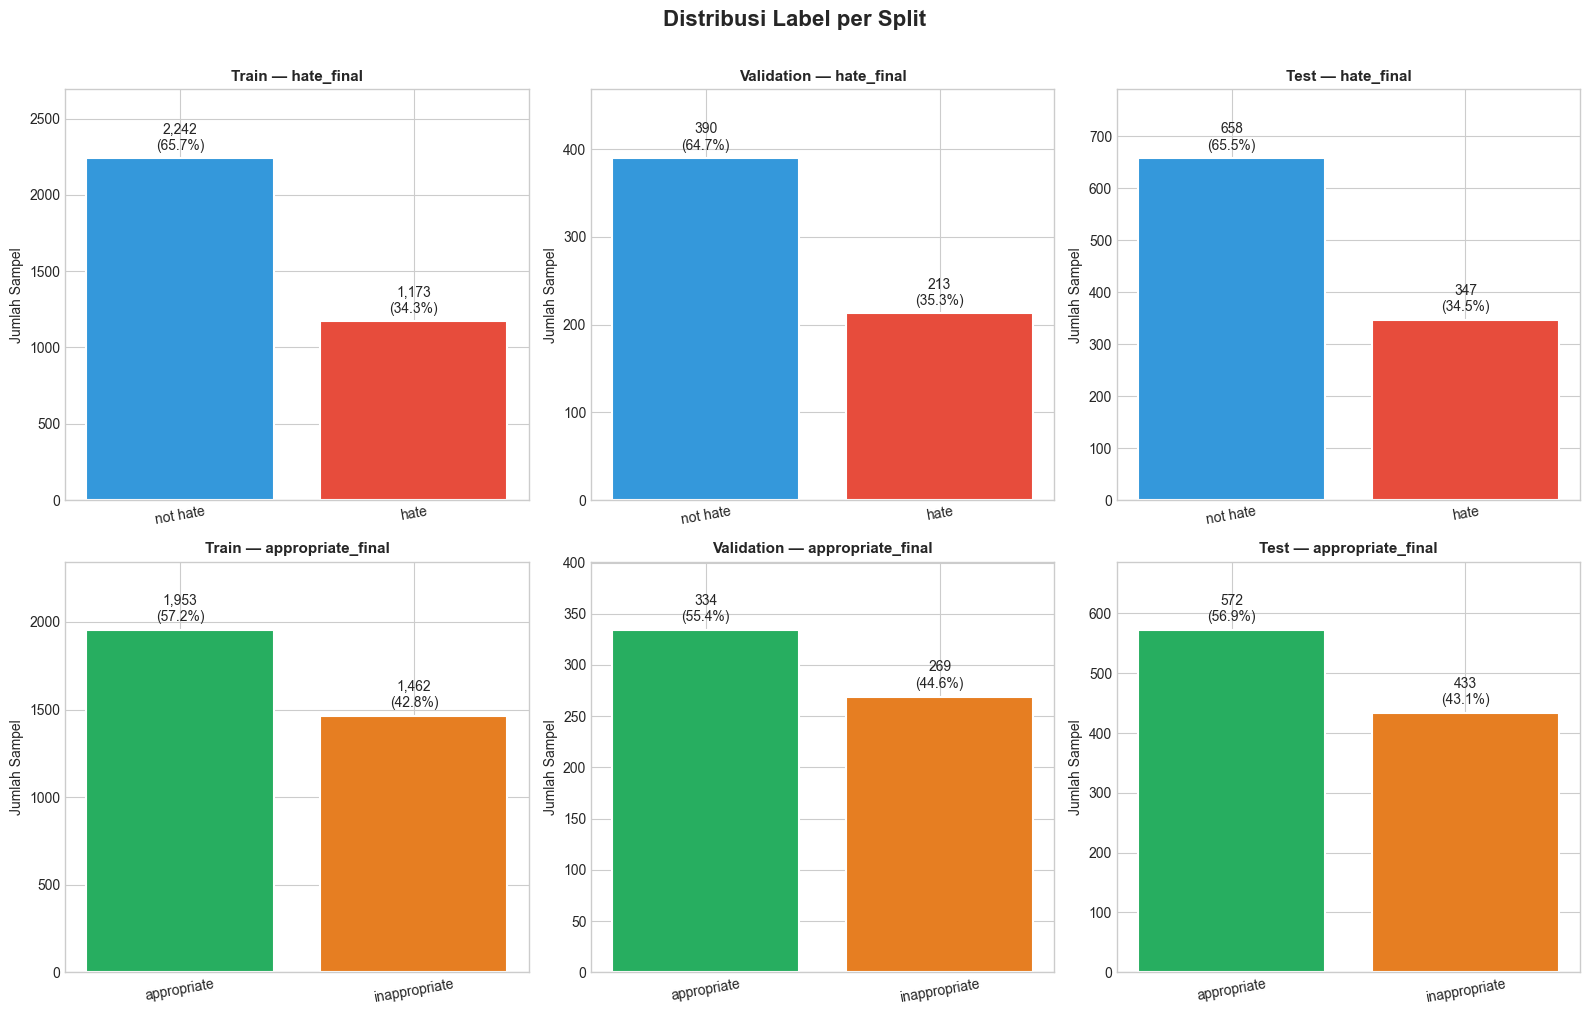

✅ Tersimpan: 01_label_distribution.png


In [18]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle("Distribusi Label per Split", fontsize=16, fontweight='bold', y=1.01)

splits = {'Train': df_train, 'Validation': df_val, 'Test': df_test}
label_pairs = [
    ('hate_final', ['hate', 'not hate'], COLORS),
    ('appropriate_final', ['appropriate', 'inappropriate'], 
     {'appropriate': '#27AE60', 'inappropriate': '#E67E22'}),
]

for row_idx, (col_name, expected_labels, color_map) in enumerate(label_pairs):
    for col_idx, (split_name, df) in enumerate(splits.items()):
        ax = axes[row_idx][col_idx]
        counts = df[col_name].value_counts()
        colors = [color_map.get(lbl, '#999') for lbl in counts.index]
        bars = ax.bar(counts.index, counts.values, color=colors, edgecolor='white', linewidth=1.5)
        
        # Tambah persentase di atas bar
        total = counts.sum()
        for bar, cnt in zip(bars, counts.values):
            ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + total*0.01,
                    f'{cnt:,}\n({cnt/total*100:.1f}%)', ha='center', va='bottom', fontsize=10)
        
        ax.set_title(f"{split_name} — {col_name}", fontsize=11, fontweight='bold')
        ax.set_ylabel("Jumlah Sampel")
        ax.set_ylim(0, counts.max() * 1.2)
        ax.tick_params(axis='x', rotation=10)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "01_label_distribution.png", dpi=150, bbox_inches='tight')
plt.show()
print("✅ Tersimpan: 01_label_distribution.png")

In [19]:
# Hitung imbalance ratio
print("=" * 50)
print("ANALISIS CLASS IMBALANCE")
print("=" * 50)

for split_name, df in splits.items():
    counts = df['hate_final'].value_counts()
    n_not_hate = counts.get('not hate', counts.get('not_hate', 0))
    n_hate = counts.get('hate', 0)
    ratio = n_not_hate / n_hate if n_hate > 0 else float('inf')
    
    print(f"\n[ {split_name} ]")
    print(f"  not hate : {n_not_hate:,}")
    print(f"  hate     : {n_hate:,}")
    print(f"  Rasio imbalance (not hate : hate) = {ratio:.2f} : 1")
    
    # Hitung class weight (inverse frequency) seperti di pipeline
    total = n_not_hate + n_hate
    w_not_hate = total / (2 * n_not_hate) if n_not_hate > 0 else 1.0
    w_hate     = total / (2 * n_hate) if n_hate > 0 else 1.0
    print(f"  Class weight not hate : {w_not_hate:.4f}")
    print(f"  Class weight hate     : {w_hate:.4f}")
    print(f"  → Sesuai pipeline: w=[{w_not_hate:.2f}, {w_hate:.2f}]")

ANALISIS CLASS IMBALANCE

[ Train ]
  not hate : 2,242
  hate     : 1,173
  Rasio imbalance (not hate : hate) = 1.91 : 1
  Class weight not hate : 0.7616
  Class weight hate     : 1.4557
  → Sesuai pipeline: w=[0.76, 1.46]

[ Validation ]
  not hate : 390
  hate     : 213
  Rasio imbalance (not hate : hate) = 1.83 : 1
  Class weight not hate : 0.7731
  Class weight hate     : 1.4155
  → Sesuai pipeline: w=[0.77, 1.42]

[ Test ]
  not hate : 658
  hate     : 347
  Rasio imbalance (not hate : hate) = 1.90 : 1
  Class weight not hate : 0.7637
  Class weight hate     : 1.4481
  → Sesuai pipeline: w=[0.76, 1.45]


In [20]:
# Korelasi hate_final dengan appropriate_final
print("Korelasi antara hate_final dan appropriate_final:")
crosstab = pd.crosstab(df_all['hate_final'], df_all['appropriate_final'], 
                        margins=True, margins_name='Total')
print(crosstab)
print("\nCatatan: Semua hate = inappropriate? (sesuai dataset description)")
hate_appropriate = df_all[
    (df_all['hate_final'] == 'hate') & (df_all['appropriate_final'] == 'appropriate')
]
print(f"  Sampel hate tapi 'appropriate': {len(hate_appropriate)} → ", end="")
print("✅ Konsisten" if len(hate_appropriate) == 0 else "⚠️ Ada inkonsistensi!")

Korelasi antara hate_final dan appropriate_final:
appropriate_final  appropriate  inappropriate  Total
hate_final                                          
hate                         0           1733   1733
not hate                  2859            431   3290
Total                     2859           2164   5023

Catatan: Semua hate = inappropriate? (sesuai dataset description)
  Sampel hate tapi 'appropriate': 0 → ✅ Konsisten


## 3. Analisis Topik

In [21]:
# Distribusi topik (PERHATIAN: satu meme bisa punya multi-topik)
# Kolom topic bisa berisi list atau string dipisah koma/semicolon

def parse_topics(topic_val):
    """Parse nilai topic ke list of strings."""
    if pd.isna(topic_val) or topic_val == '':
        return ['Unknown']
    # Coba parse sebagai JSON list
    if isinstance(topic_val, list):
        return topic_val
    s = str(topic_val).strip()
    # Coba JSON
    if s.startswith('['):
        try:
            parsed = json.loads(s)
            if isinstance(parsed, list):
                return [str(t).strip() for t in parsed]
        except:
            pass
    # Split by common delimiters
    for sep in [';', ',', '|']:
        if sep in s:
            return [t.strip() for t in s.split(sep) if t.strip()]
    return [s]

# Ekspansi topik
df_all['topics_list'] = df_all['topic'].apply(parse_topics)

# Tampilkan contoh
print("Contoh nilai kolom 'topic':")
for val in df_all['topic'].dropna().unique()[:10]:
    print(f"  {repr(val):60s} → {parse_topics(val)}")

Contoh nilai kolom 'topic':
  'social sub-groups'                                          → ['social sub-groups']
  'religion'                                                   → ['religion']
  'gender, social sub-groups'                                  → ['gender', 'social sub-groups']
  'individual, institutions'                                   → ['individual', 'institutions']
  'gender, religion'                                           → ['gender', 'religion']
  'social sub-groups, gender'                                  → ['social sub-groups', 'gender']
  'individual, political'                                      → ['individual', 'political']
  'national origin, social sub-groups'                         → ['national origin', 'social sub-groups']
  'gender'                                                     → ['gender']
  'national origin'                                            → ['national origin']


In [22]:
# Hitung frekuensi setiap topik
all_topics = [t for topics in df_all['topics_list'] for t in topics]
topic_counts = Counter(all_topics)

print("\nFrekuensi topik (seluruh dataset):")
for topic, cnt in topic_counts.most_common():
    print(f"  {topic:40s}: {cnt:,} ({cnt/len(df_all)*100:.1f}%)")

print(f"\nTotal meme (termasuk multi-topik): {sum(topic_counts.values()):,}")
print(f"Total meme unik: {len(df_all):,}")
print(f"Rata-rata topik per meme: {sum(topic_counts.values())/len(df_all):.2f}")


Frekuensi topik (seluruh dataset):
  social sub-groups                       : 2,849 (56.7%)
  gender                                  : 853 (17.0%)
  political                               : 668 (13.3%)
  individual                              : 665 (13.2%)
  institutions                            : 432 (8.6%)
  national origin                         : 346 (6.9%)
  religion                                : 241 (4.8%)
  Unknown                                 : 228 (4.5%)

Total meme (termasuk multi-topik): 6,282
Total meme unik: 5,023
Rata-rata topik per meme: 1.25


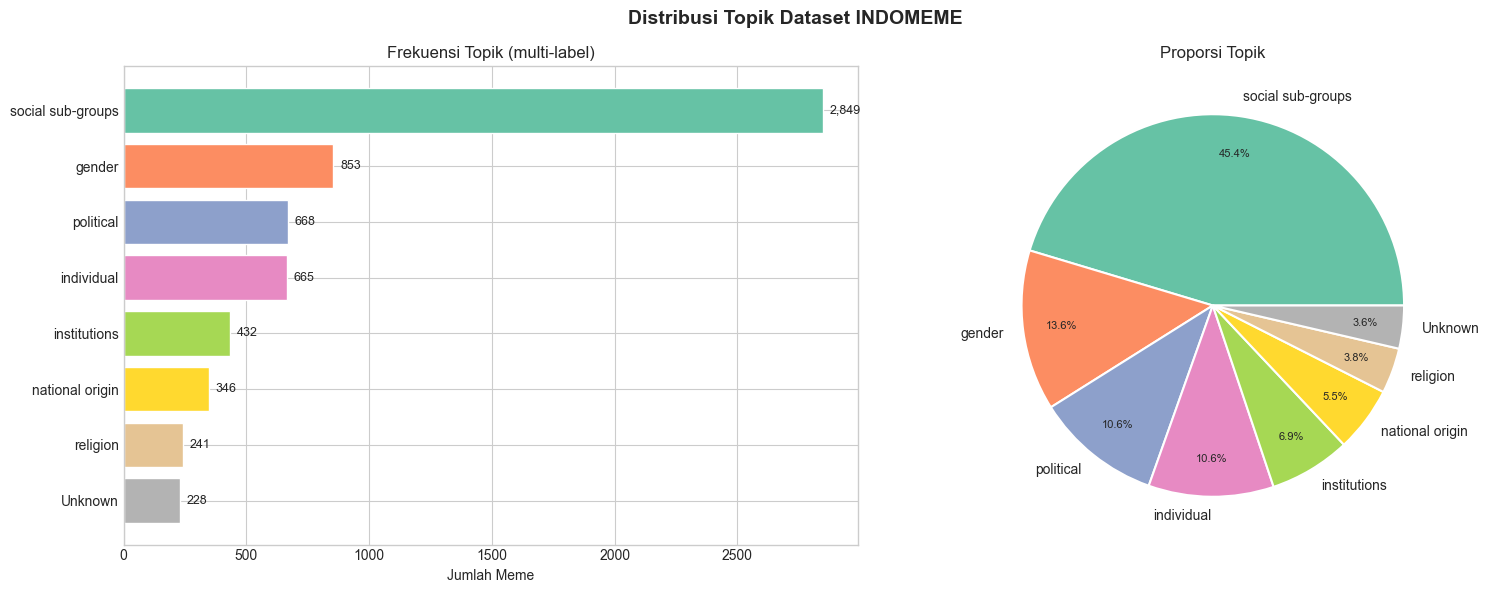

✅ Tersimpan: 02_topic_distribution.png


In [23]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle("Distribusi Topik Dataset INDOMEME", fontsize=14, fontweight='bold')

# Plot 1: Frekuensi topik
ax1 = axes[0]
topics_sorted = sorted(topic_counts.items(), key=lambda x: x[1], reverse=True)
topic_names = [t[0] for t in topics_sorted]
topic_freqs = [t[1] for t in topics_sorted]
colors_bar = plt.cm.Set2(np.linspace(0, 1, len(topic_names)))
bars = ax1.barh(topic_names, topic_freqs, color=colors_bar, edgecolor='white')
for bar, freq in zip(bars, topic_freqs):
    ax1.text(bar.get_width() + max(topic_freqs)*0.01, bar.get_y() + bar.get_height()/2,
             f'{freq:,}', va='center', fontsize=9)
ax1.set_xlabel("Jumlah Meme")
ax1.set_title("Frekuensi Topik (multi-label)")
ax1.invert_yaxis()

# Plot 2: Pie chart proporsi
ax2 = axes[1]
wedges, texts, autotexts = ax2.pie(
    topic_freqs, labels=topic_names, autopct='%1.1f%%',
    colors=colors_bar, pctdistance=0.8,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}
)
for autotext in autotexts:
    autotext.set_fontsize(8)
ax2.set_title("Proporsi Topik")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "02_topic_distribution.png", dpi=150, bbox_inches='tight')
plt.show()
print("✅ Tersimpan: 02_topic_distribution.png")

In [24]:
# KRITIS: Hate rate per topik (sesuai temuan Pamungkas)
# Untuk multi-topik, expand baris

# Buat df expanded dengan satu baris per topik
df_expanded_topic = df_all.explode('topics_list').copy()
df_expanded_topic = df_expanded_topic.reset_index(drop=True)
df_expanded_topic = df_expanded_topic.rename(columns={'topics_list': 'topic_single'})

# Hitung hate rate per topik
hate_per_topic = df_expanded_topic.groupby('topic_single').agg(
    total=('hate_final', 'count'),
    n_hate=('hate_final', lambda x: (x == 'hate').sum()),
    n_not_hate=('hate_final', lambda x: (x == 'not hate').sum()),
).reset_index()
hate_per_topic['hate_rate'] = hate_per_topic['n_hate'] / hate_per_topic['total'] * 100
hate_per_topic = hate_per_topic.sort_values('hate_rate', ascending=False)

print("Hate rate per topik (diurutkan dari tertinggi):")
print(hate_per_topic.to_string(index=False))

Hate rate per topik (diurutkan dari tertinggi):
     topic_single  total  n_hate  n_not_hate  hate_rate
        political    668     543         125  81.287425
  national origin    346     270          76  78.034682
       individual    665     465         200  69.924812
     institutions    432     273         159  63.194444
           gender    853     324         529  37.983587
         religion    241      57         184  23.651452
social sub-groups   2849     583        2266  20.463320
          Unknown    228       2         226   0.877193


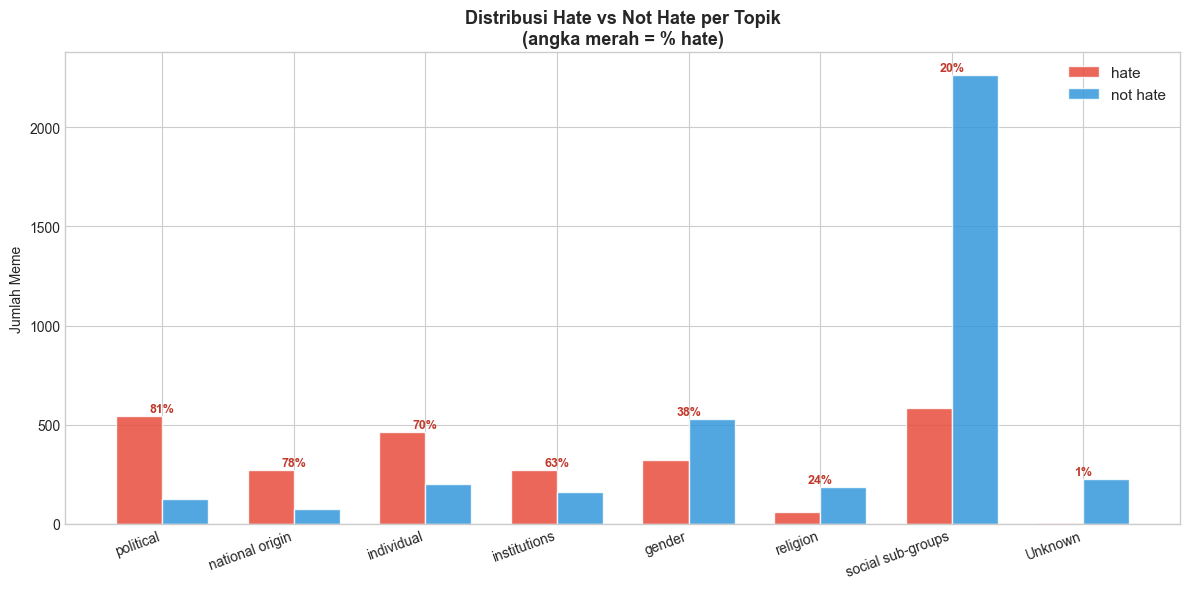

✅ Tersimpan: 03_hate_per_topic.png


In [25]:
fig, ax = plt.subplots(figsize=(12, 6))

topics = hate_per_topic['topic_single']
x = np.arange(len(topics))
width = 0.35

bars_hate = ax.bar(x - width/2, hate_per_topic['n_hate'], width,
                    label='hate', color=COLORS['hate'], alpha=0.85, edgecolor='white')
bars_nothate = ax.bar(x + width/2, hate_per_topic['n_not_hate'], width,
                       label='not hate', color=COLORS['not hate'], alpha=0.85, edgecolor='white')

# Tambah hate rate sebagai teks
for i, (_, row) in enumerate(hate_per_topic.iterrows()):
    ax.text(i, max(row['n_hate'], row['n_not_hate']) + 5,
            f"{row['hate_rate']:.0f}%", ha='center', va='bottom',
            fontsize=9, fontweight='bold', color='#C0392B')

ax.set_xticks(x)
ax.set_xticklabels(topics, rotation=20, ha='right', fontsize=10)
ax.set_ylabel("Jumlah Meme")
ax.set_title("Distribusi Hate vs Not Hate per Topik\n(angka merah = % hate)",
             fontsize=13, fontweight='bold')
ax.legend(fontsize=11)

# Annotasi kritis
ax.axhline(y=0, color='black', linewidth=0.5)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "03_hate_per_topic.png", dpi=150, bbox_inches='tight')
plt.show()
print("✅ Tersimpan: 03_hate_per_topic.png")

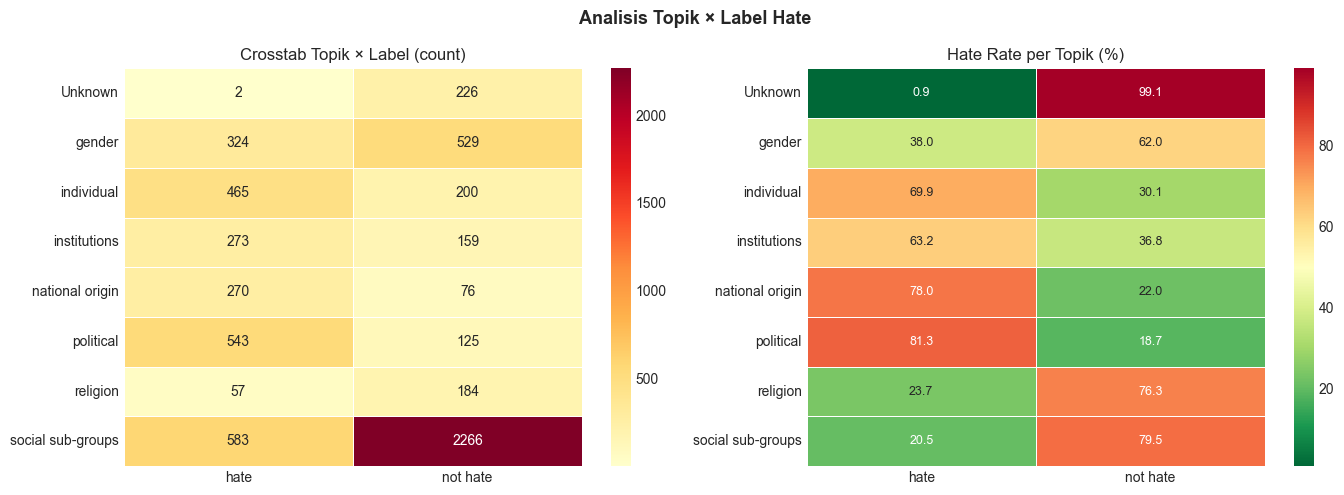

✅ Tersimpan: 04_topic_hate_heatmap.png

🔍 TEMUAN KRITIS (relevan untuk pipeline):
  political                          : 81.3% hate  ⚠️ TINGGI
  national origin                    : 78.0% hate  ⚠️ TINGGI
  individual                         : 69.9% hate  ⚠️ TINGGI
  institutions                       : 63.2% hate  ⚠️ TINGGI
  gender                             : 38.0% hate  
  religion                           : 23.7% hate  
  social sub-groups                  : 20.5% hate  
  Unknown                            : 0.9% hate  ✅ RENDAH


In [26]:
# Heatmap: Topik × Hate (normalized)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Raw counts
pivot_raw = pd.crosstab(df_expanded_topic['topic_single'], df_expanded_topic['hate_final'])
sns.heatmap(pivot_raw, annot=True, fmt='d', cmap='YlOrRd',
            ax=axes[0], linewidths=0.5)
axes[0].set_title("Crosstab Topik × Label (count)")
axes[0].set_xlabel("")
axes[0].set_ylabel("")

# Row-normalized (hate rate per topik)
pivot_norm = pivot_raw.div(pivot_raw.sum(axis=1), axis=0) * 100
sns.heatmap(pivot_norm, annot=True, fmt='.1f', cmap='RdYlGn_r',
            ax=axes[1], linewidths=0.5,
            annot_kws={'size': 9})
axes[1].set_title("Hate Rate per Topik (%)")
axes[1].set_xlabel("")
axes[1].set_ylabel("")

plt.suptitle("Analisis Topik × Label Hate", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / "04_topic_hate_heatmap.png", dpi=150, bbox_inches='tight')
plt.show()
print("✅ Tersimpan: 04_topic_hate_heatmap.png")

# TEMUAN KRITIS
print("\n🔍 TEMUAN KRITIS (relevan untuk pipeline):")
for _, row in hate_per_topic.iterrows():
    flag = "⚠️ TINGGI" if row['hate_rate'] > 60 else ("✅ RENDAH" if row['hate_rate'] < 15 else "")
    print(f"  {row['topic_single']:35s}: {row['hate_rate']:.1f}% hate  {flag}")

## 4. Analisis Teks (OCR)

In [27]:
# Hitung statistik dasar teks OCR
def text_stats(df, col):
    """Hitung statistik teks: panjang token, char, missing."""
    texts = df[col].fillna('')
    char_lens = texts.str.len()
    word_lens = texts.str.split().str.len().fillna(0)
    missing = (texts == '') | (texts.str.lower().isin(['none', 'null', 'nan', '-', 'no text']))
    
    return {
        'n_total': len(df),
        'n_missing': missing.sum(),
        'pct_missing': missing.mean() * 100,
        'char_mean': char_lens.mean(),
        'char_median': char_lens.median(),
        'char_max': char_lens.max(),
        'char_p95': char_lens.quantile(0.95),
        'word_mean': word_lens.mean(),
        'word_median': word_lens.median(),
        'word_max': word_lens.max(),
        'word_p95': word_lens.quantile(0.95),
        'n_empty_str': (texts.str.strip() == '').sum(),
    }

print("Statistik OCR per split:")
for split_name, df in splits.items():
    stats = text_stats(df, 'ocr')
    print(f"\n[ {split_name} ]")
    print(f"  Missing / kosong : {stats['n_missing']:,} ({stats['pct_missing']:.1f}%)")
    print(f"  Panjang karakter : mean={stats['char_mean']:.1f}, median={stats['char_median']:.0f}, max={stats['char_max']:.0f}, p95={stats['char_p95']:.0f}")
    print(f"  Panjang kata     : mean={stats['word_mean']:.1f}, median={stats['word_median']:.0f}, max={stats['word_max']:.0f}, p95={stats['word_p95']:.0f}")

Statistik OCR per split:

[ Train ]
  Missing / kosong : 0 (0.0%)
  Panjang karakter : mean=86.6, median=70, max=944, p95=218
  Panjang kata     : mean=14.3, median=12, max=131, p95=35

[ Validation ]
  Missing / kosong : 0 (0.0%)
  Panjang karakter : mean=83.1, median=72, max=355, p95=202
  Panjang kata     : mean=13.8, median=12, max=63, p95=34

[ Test ]
  Missing / kosong : 0 (0.0%)
  Panjang karakter : mean=86.4, median=68, max=912, p95=215
  Panjang kata     : mean=14.3, median=12, max=165, p95=36


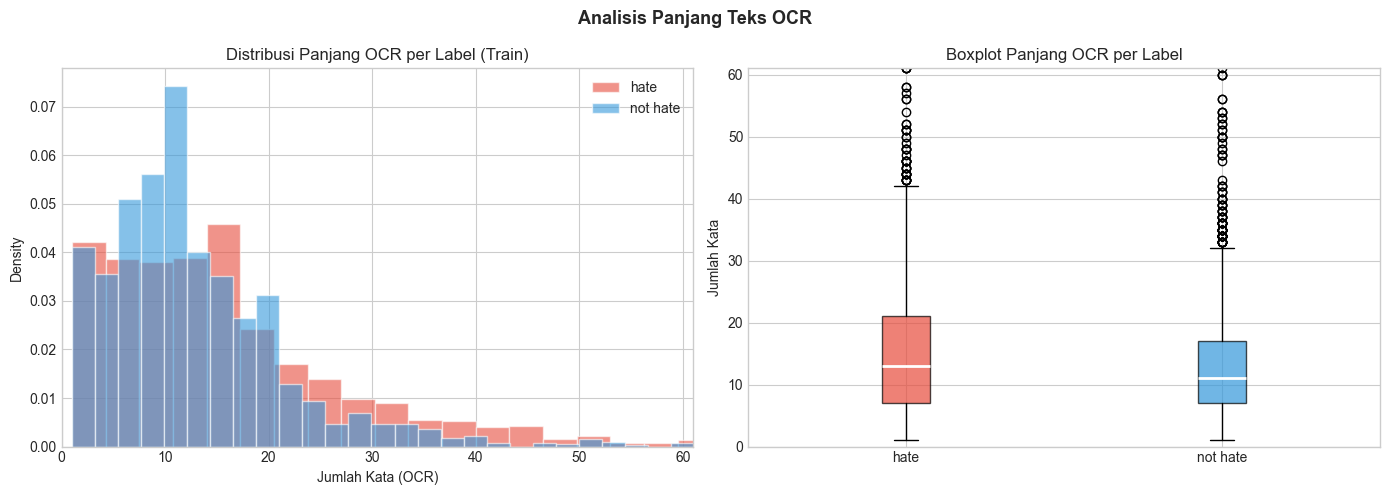

✅ Tersimpan: 05_ocr_length_distribution.png


In [28]:
# Distribusi panjang teks OCR — per label
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df_train['ocr_word_count'] = df_train['ocr'].fillna('').str.split().str.len()

# Histogram per label
ax = axes[0]
for label in ['hate', 'not hate']:
    subset = df_train[df_train['hate_final'] == label]['ocr_word_count']
    ax.hist(subset, bins=40, alpha=0.6, label=label, color=COLORS[label],
            density=True, edgecolor='white')
ax.set_xlabel("Jumlah Kata (OCR)")
ax.set_ylabel("Density")
ax.set_title("Distribusi Panjang OCR per Label (Train)")
ax.legend()
ax.set_xlim(0, df_train['ocr_word_count'].quantile(0.99))

# Boxplot per label
ax2 = axes[1]
data_box = [df_train[df_train['hate_final'] == lbl]['ocr_word_count'].values
            for lbl in ['hate', 'not hate']]
bp = ax2.boxplot(data_box, labels=['hate', 'not hate'], patch_artist=True,
                  medianprops={'color': 'white', 'linewidth': 2})
for patch, color in zip(bp['boxes'], [COLORS['hate'], COLORS['not hate']]):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
ax2.set_ylabel("Jumlah Kata")
ax2.set_title("Boxplot Panjang OCR per Label")
ax2.set_ylim(0, df_train['ocr_word_count'].quantile(0.99))

plt.suptitle("Analisis Panjang Teks OCR", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / "05_ocr_length_distribution.png", dpi=150, bbox_inches='tight')
plt.show()
print("✅ Tersimpan: 05_ocr_length_distribution.png")

In [29]:
# Analisis OCR kosong / pendek per label
print("Analisis OCR kosong/sangat pendek per label (train):")
thresholds = [0, 1, 3, 5, 10]

print(f"{'Threshold':>12} | {'hate':>10} | {'not hate':>10} | {'Catatan':}")
print("-" * 60)
for thresh in thresholds:
    for label in ['hate', 'not hate']:
        subset = df_train[df_train['hate_final'] == label]
        n_short = (subset['ocr_word_count'] <= thresh).sum()
        pct = n_short / len(subset) * 100
        if label == 'hate':
            row_hate = f"{n_short:,} ({pct:.1f}%)"
        else:
            row_nothate = f"{n_short:,} ({pct:.1f}%)"
    note = "← meme tanpa teks" if thresh == 0 else ""
    print(f"  word ≤ {thresh:2d}     | {row_hate:>10} | {row_nothate:>10} | {note}")

Analisis OCR kosong/sangat pendek per label (train):
   Threshold |       hate |   not hate | Catatan
------------------------------------------------------------
  word ≤  0     |   0 (0.0%) |   0 (0.0%) | ← meme tanpa teks
  word ≤  1     |  29 (2.5%) |  52 (2.3%) | 
  word ≤  3     | 108 (9.2%) | 205 (9.1%) | 
  word ≤  5     | 196 (16.7%) | 382 (17.0%) | 
  word ≤ 10     | 453 (38.6%) | 1,040 (46.4%) | 


In [30]:
# Analisis kosakata OCR
import re

def tokenize_simple(text):
    if pd.isna(text) or text == '':
        return []
    return re.findall(r'\b[a-zA-Z]+\b', str(text).lower())

# Kosakata training
all_tokens_hate    = [t for text in df_train[df_train['hate_final']=='hate']['ocr'] 
                       for t in tokenize_simple(text)]
all_tokens_nothate = [t for text in df_train[df_train['hate_final']=='not hate']['ocr'] 
                       for t in tokenize_simple(text)]

vocab_hate    = Counter(all_tokens_hate)
vocab_nothate = Counter(all_tokens_nothate)

print(f"Ukuran vocabulary OCR:")
print(f"  hate (total token)   : {len(all_tokens_hate):,}")
print(f"  hate (unique token)  : {len(vocab_hate):,}")
print(f"  not hate (total)     : {len(all_tokens_nothate):,}")
print(f"  not hate (unique)    : {len(vocab_nothate):,}")

print(f"\nTop 20 token OCR — hate:")
for w, c in vocab_hate.most_common(20):
    print(f"  {w:20s}: {c:,}")

print(f"\nTop 20 token OCR — not hate:")
for w, c in vocab_nothate.most_common(20):
    print(f"  {w:20s}: {c:,}")

Ukuran vocabulary OCR:
  hate (total token)   : 18,211
  hate (unique token)  : 6,195
  not hate (total)     : 28,189
  not hate (unique)    : 7,461

Top 20 token OCR — hate:
  di                  : 237
  yang                : 223
  gw                  : 121
  orang               : 117
  dan                 : 113
  lu                  : 106
  ada                 : 91
  gak                 : 91
  ini                 : 87
  itu                 : 87
  indonesia           : 81
  tapi                : 78
  dari                : 74
  bisa                : 71
  yg                  : 70
  ga                  : 68
  aku                 : 67
  anak                : 64
  ketika              : 64
  jadi                : 63

Top 20 token OCR — not hate:
  di                  : 445
  yang                : 416
  gw                  : 362
  aku                 : 269
  lu                  : 256
  ketika              : 248
  dan                 : 209
  ada                 : 187
  ini                 : 1

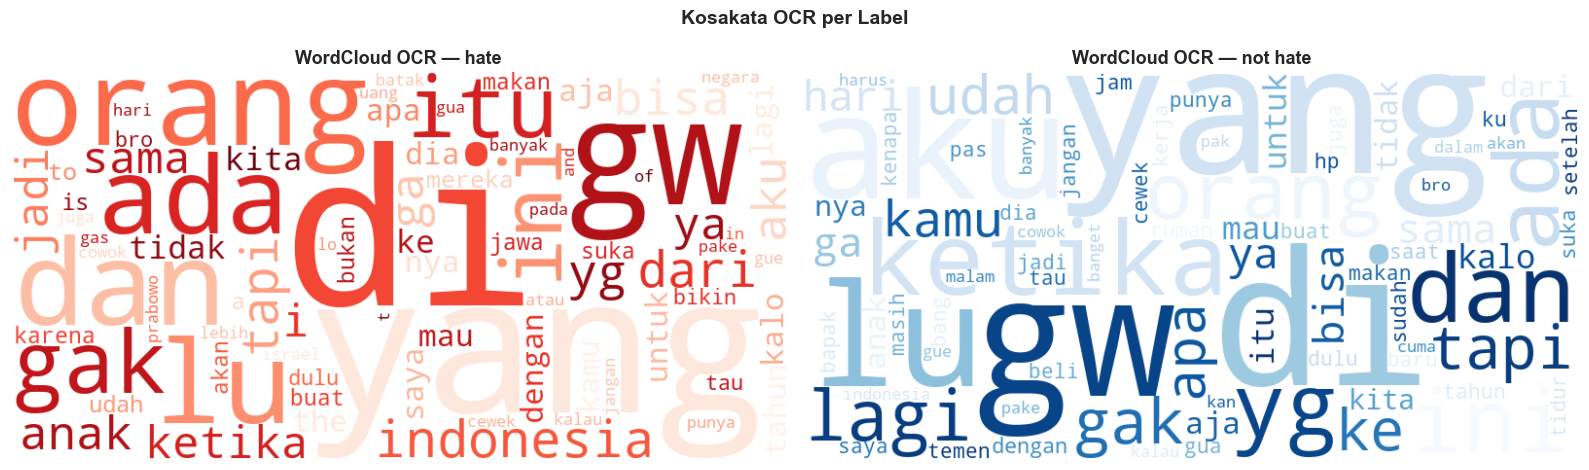

✅ Tersimpan: 06_wordcloud_ocr.png


In [31]:
# WordCloud OCR per label
try:
    from wordcloud import WordCloud
    
    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    
    for ax, (label, vocab, color) in zip(axes, [
        ('hate',     vocab_hate,    COLORS['hate']),
        ('not hate', vocab_nothate, COLORS['not hate']),
    ]):
        if vocab:
            wc = WordCloud(
                width=800, height=400,
                background_color='white',
                colormap='Reds' if label == 'hate' else 'Blues',
                max_words=80,
                min_font_size=8,
            ).generate_from_frequencies(dict(vocab.most_common(200)))
            ax.imshow(wc, interpolation='bilinear')
        ax.axis('off')
        ax.set_title(f"WordCloud OCR — {label}", fontsize=13, fontweight='bold')
    
    plt.suptitle("Kosakata OCR per Label", fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "06_wordcloud_ocr.png", dpi=150, bbox_inches='tight')
    plt.show()
    print("✅ Tersimpan: 06_wordcloud_ocr.png")
except ImportError:
    print("⚠️ wordcloud tidak terinstall. Jalankan: pip install wordcloud")

## 5. Analisis Caption

In [32]:
# Statistik caption
print("Statistik Caption per split:")
for split_name, df in splits.items():
    stats = text_stats(df, 'caption')
    print(f"\n[ {split_name} ]")
    print(f"  Missing / kosong : {stats['n_missing']:,} ({stats['pct_missing']:.1f}%)")
    print(f"  Panjang karakter : mean={stats['char_mean']:.1f}, median={stats['char_median']:.0f}, p95={stats['char_p95']:.0f}")
    print(f"  Panjang kata     : mean={stats['word_mean']:.1f}, median={stats['word_median']:.0f}, p95={stats['word_p95']:.0f}")

Statistik Caption per split:

[ Train ]
  Missing / kosong : 0 (0.0%)
  Panjang karakter : mean=140.7, median=140, p95=169
  Panjang kata     : mean=18.1, median=18, p95=22

[ Validation ]
  Missing / kosong : 0 (0.0%)
  Panjang karakter : mean=140.6, median=141, p95=172
  Panjang kata     : mean=18.1, median=18, p95=22

[ Test ]
  Missing / kosong : 0 (0.0%)
  Panjang karakter : mean=141.0, median=140, p95=172
  Panjang kata     : mean=18.2, median=18, p95=22


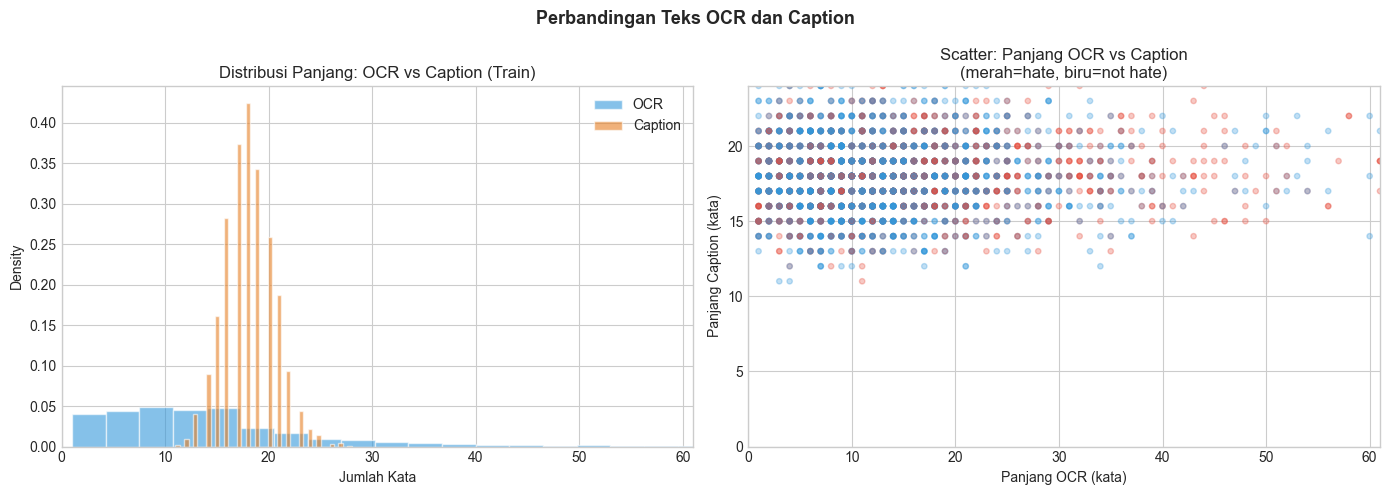

✅ Tersimpan: 07_caption_vs_ocr.png


In [33]:
# Distribusi panjang caption vs OCR (train)
df_train['caption_word_count'] = df_train['caption'].fillna('').str.split().str.len()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram perbandingan OCR vs caption
ax1 = axes[0]
ax1.hist(df_train['ocr_word_count'], bins=40, alpha=0.6,
         label='OCR', color='#3498DB', density=True, edgecolor='white')
ax1.hist(df_train['caption_word_count'], bins=40, alpha=0.6,
         label='Caption', color='#E67E22', density=True, edgecolor='white')
ax1.set_xlabel("Jumlah Kata")
ax1.set_ylabel("Density")
ax1.set_title("Distribusi Panjang: OCR vs Caption (Train)")
ax1.legend()
xlim = max(df_train['ocr_word_count'].quantile(0.99),
           df_train['caption_word_count'].quantile(0.99))
ax1.set_xlim(0, xlim)

# Scatter: OCR len vs caption len
ax2 = axes[1]
colors_scatter = [COLORS['hate'] if l == 'hate' else COLORS['not hate']
                  for l in df_train['hate_final']]
ax2.scatter(df_train['ocr_word_count'], df_train['caption_word_count'],
            c=colors_scatter, alpha=0.3, s=15)
ax2.set_xlabel("Panjang OCR (kata)")
ax2.set_ylabel("Panjang Caption (kata)")
ax2.set_title("Scatter: Panjang OCR vs Caption\n(merah=hate, biru=not hate)")
ax2.set_xlim(0, df_train['ocr_word_count'].quantile(0.99))
ax2.set_ylim(0, df_train['caption_word_count'].quantile(0.99))

plt.suptitle("Perbandingan Teks OCR dan Caption", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / "07_caption_vs_ocr.png", dpi=150, bbox_inches='tight')
plt.show()
print("✅ Tersimpan: 07_caption_vs_ocr.png")

In [34]:
# Panjang teks gabungan: simulasi input IndoBERTweet
# Format: [topik] caption [SEP] ocr
# Max token IndoBERTweet = 512

def estimate_combined_length(row):
    topic = str(row.get('topic', '')).strip()
    ocr   = str(row.get('ocr', '')).strip()
    cap   = str(row.get('caption', '')).strip()
    # Estimasi kasar: karakter / 4 ≈ token subword
    combined = f"[{topic}] {cap} [SEP] {ocr}"
    return len(combined.split())  # word-level proxy

df_train['combined_len_words'] = df_train.apply(estimate_combined_length, axis=1)

# Estimasi token (rough: 1 word ≈ 1.2 subword untuk Bahasa Indonesia)
df_train['est_tokens'] = (df_train['combined_len_words'] * 1.2).astype(int)

print("Estimasi panjang input teks gabungan [topik + caption + SEP + ocr]:")
print(f"  Mean kata    : {df_train['combined_len_words'].mean():.1f}")
print(f"  Median kata  : {df_train['combined_len_words'].median():.0f}")
print(f"  P95 kata     : {df_train['combined_len_words'].quantile(0.95):.0f}")
print(f"  Max kata     : {df_train['combined_len_words'].max():.0f}")
print(f"\n  Est. P95 token (subword): {df_train['est_tokens'].quantile(0.95):.0f}")
print(f"  Est. max token          : {df_train['est_tokens'].max():.0f}")
pct_exceeds_512 = (df_train['est_tokens'] > 512).mean() * 100
print(f"\n  ⚠️  Estimasi sampel > 512 token: {pct_exceeds_512:.1f}%")
print(f"     → {'PERHATIAN: truncation diperlukan!' if pct_exceeds_512 > 5 else 'OK, truncation minimal'}")

Estimasi panjang input teks gabungan [topik + caption + SEP + ocr]:
  Mean kata    : 35.3
  Median kata  : 33
  P95 kata     : 57
  Max kata     : 153

  Est. P95 token (subword): 68
  Est. max token          : 183

  ⚠️  Estimasi sampel > 512 token: 0.0%
     → OK, truncation minimal


## 6. Analisis Gambar

In [ ]:
# Analisis dimensi dan properti gambar (sampling 500 dari train)
def analyze_images(df, split_name, n_sample=500):
    """Analisis properti gambar dari sampel."""
    sample_df = df[df['local_image_path'] != ''].sample(
        min(n_sample, len(df)), random_state=42
    )
    
    widths, heights, modes, ratios = [], [], [], []
    failed = 0
    
    for _, row in tqdm(sample_df.iterrows(), total=len(sample_df),
                        desc=f"Analisis gambar [{split_name}]"):
        try:
            img = Image.open(row['local_image_path'])
            w, h = img.size
            widths.append(w)
            heights.append(h)
            modes.append(img.mode)
            ratios.append(w / h)
        except Exception:
            failed += 1
    
    print(f"\n[ {split_name} — {len(sample_df)} sampel, {failed} gagal dibuka ]")
    if widths:
        print(f"  Lebar  : mean={np.mean(widths):.0f}, min={min(widths)}, max={max(widths)}, median={np.median(widths):.0f}")
        print(f"  Tinggi : mean={np.mean(heights):.0f}, min={min(heights)}, max={max(heights)}, median={np.median(heights):.0f}")
        print(f"  Aspect ratio : mean={np.mean(ratios):.2f}, min={min(ratios):.2f}, max={max(ratios):.2f}")
        mode_counts = Counter(modes)
        print(f"  Mode warna : {dict(mode_counts)}")
    
    return widths, heights, modes, ratios

image_stats = {}
for split_name, df in splits.items():
    w, h, m, r = analyze_images(df, split_name)
    image_stats[split_name] = {'widths': w, 'heights': h, 'modes': m, 'ratios': r}

Analisis gambar [Train]:  50%|████▉     | 248/500 [00:03<00:03, 76.88it/s]

In [ ]:
# Visualisasi distribusi dimensi gambar (train)
train_stats = image_stats.get('train', {})
if train_stats.get('widths'):
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))

    # Histogram width
    axes[0].hist(train_stats['widths'], bins=40, color='#3498DB', edgecolor='white', alpha=0.8)
    axes[0].axvline(224, color='red', linestyle='--', linewidth=2, label='Target resize (224)')
    axes[0].set_xlabel("Lebar (px)")
    axes[0].set_ylabel("Count")
    axes[0].set_title("Distribusi Lebar Gambar")
    axes[0].legend()

    # Histogram height
    axes[1].hist(train_stats['heights'], bins=40, color='#E74C3C', edgecolor='white', alpha=0.8)
    axes[1].axvline(224, color='blue', linestyle='--', linewidth=2, label='Target resize (224)')
    axes[1].set_xlabel("Tinggi (px)")
    axes[1].set_title("Distribusi Tinggi Gambar")
    axes[1].legend()

    # Scatter width vs height
    axes[2].scatter(train_stats['widths'], train_stats['heights'],
                    alpha=0.3, s=15, color='#27AE60')
    axes[2].axhline(224, color='red', linestyle='--', linewidth=1, alpha=0.7)
    axes[2].axvline(224, color='red', linestyle='--', linewidth=1, alpha=0.7)
    axes[2].set_xlabel("Lebar (px)")
    axes[2].set_ylabel("Tinggi (px)")
    axes[2].set_title("Scatter Lebar × Tinggi")

    plt.suptitle("Distribusi Dimensi Gambar (Train)", fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "08_image_dimensions.png", dpi=150, bbox_inches='tight')
    plt.show()
    print("✅ Tersimpan: 08_image_dimensions.png")

    # Statistik aspect ratio
    ratios = train_stats['ratios']
    pct_sq   = sum(0.9 <= r <= 1.1 for r in ratios) / len(ratios) * 100
    pct_wide = sum(r > 1.5 for r in ratios) / len(ratios) * 100
    pct_tall = sum(r < 0.67 for r in ratios) / len(ratios) * 100
    print(f"\nAspect ratio train:")
    print(f"  ~Square   (0.9-1.1) : {pct_sq:.1f}%")
    print(f"  Landscape (>1.5)    : {pct_wide:.1f}%")
    print(f"  Portrait  (<0.67)   : {pct_tall:.1f}%")

In [ ]:
# Tampilkan sampel gambar per label (3 hate + 3 not hate)
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
fig.suptitle("Contoh Meme: Hate (atas) vs Not Hate (bawah)", fontsize=13, fontweight='bold')

for row_idx, label in enumerate(['hate', 'not hate']):
    subset = df_train[
        (df_train['hate_final'] == label) &
        (df_train['local_image_path'] != '')
    ].sample(3, random_state=42)
    
    for col_idx, (_, row) in enumerate(subset.iterrows()):
        ax = axes[row_idx][col_idx]
        try:
            img = Image.open(row['local_image_path'])
            ax.imshow(img)
        except:
            ax.text(0.5, 0.5, 'Gambar tidak ditemukan', ha='center', va='center',
                    transform=ax.transAxes)
        
        # Tampilkan OCR singkat sebagai caption
        ocr_short = str(row.get('ocr', ''))[:50] + '...' if len(str(row.get('ocr',''))) > 50 else str(row.get('ocr',''))
        topic_short = str(row.get('topic', ''))[:30]
        ax.set_title(f"[{label.upper()}]\nTopik: {topic_short}\nOCR: {ocr_short}",
                     fontsize=7, loc='left')
        ax.axis('off')

plt.tight_layout()
plt.savefig(FIGURES_DIR / "09_sample_memes.png", dpi=150, bbox_inches='tight')
plt.show()
print("✅ Tersimpan: 09_sample_memes.png")

## 7. Analisis Multimodal: Korelasi Teks × Gambar × Label

In [ ]:
# Analisis: meme dengan OCR kosong — apakah masih terdeteksi hate?
print("Analisis meme dengan OCR kosong/sangat pendek:")
df_train['ocr_is_empty'] = df_train['ocr_word_count'] == 0

for grp_name, grp in df_train.groupby('ocr_is_empty'):
    label = 'Kosong (0 kata)' if grp_name else 'Ada teks'
    hate_pct = (grp['hate_final'] == 'hate').mean() * 100
    print(f"  OCR {label:20s}: {len(grp):,} sampel, hate={hate_pct:.1f}%")

print("\n→ Jika meme tanpa teks masih punya hate rate tinggi, gambar adalah sinyal kuat.")
print("  Ini mendukung pentingnya ICAM untuk fusion multimodal.")

In [ ]:
# Korelasi panjang teks dengan label hate
from scipy import stats

hate_binary = (df_train['hate_final'] == 'hate').astype(int)

print("Korelasi fitur teks dengan label hate:")
for feat_name, feat_vals in [
    ('OCR word count',     df_train['ocr_word_count']),
    ('Caption word count', df_train['caption_word_count']),
    ('Combined length',    df_train['combined_len_words']),
]:
    r, p = stats.pointbiserialr(hate_binary, feat_vals.fillna(0))
    significance = '✅ signifikan' if p < 0.05 else '⚠️ tidak signifikan'
    print(f"  {feat_name:25s}: r={r:+.4f}, p={p:.4f}  {significance}")

In [ ]:
# Heatmap korelasi fitur numerik
numeric_feats = df_train[[
    'ocr_word_count', 'caption_word_count', 'combined_len_words'
]].copy()
numeric_feats['hate_label'] = (df_train['hate_final'] == 'hate').astype(int)

fig, ax = plt.subplots(figsize=(7, 5))
corr_matrix = numeric_feats.corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)
sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='coolwarm',
            center=0, vmin=-1, vmax=1,
            linewidths=0.5, ax=ax)
ax.set_title("Korelasi Fitur Numerik", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / "10_correlation_matrix.png", dpi=150, bbox_inches='tight')
plt.show()
print("✅ Tersimpan: 10_correlation_matrix.png")

In [ ]:
# Analisis per topik: panjang teks dan gambar
df_train['topics_list'] = df_train['topic'].apply(parse_topics)
df_expanded_train = df_train.explode('topics_list').copy()
df_expanded_train = df_expanded_train.reset_index(drop=True)
df_expanded_train = df_expanded_train.rename(columns={'topics_list': 'topic_single'})

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Boxplot panjang OCR per topik
topic_order = hate_per_topic['topic_single'].tolist()
data_by_topic = [df_expanded_train[df_expanded_train['topic_single'] == t]['ocr_word_count'].values
                  for t in topic_order]
axes[0].boxplot(data_by_topic, labels=topic_order, patch_artist=True,
                medianprops={'color': 'white', 'linewidth': 2})
axes[0].set_xticklabels(topic_order, rotation=20, ha='right')
axes[0].set_ylabel("Jumlah Kata")
axes[0].set_title("Distribusi Panjang OCR per Topik")

# Boxplot panjang caption per topik
data_cap_by_topic = [df_expanded_train[df_expanded_train['topic_single'] == t]['caption_word_count'].values
                      for t in topic_order]
axes[1].boxplot(data_cap_by_topic, labels=topic_order, patch_artist=True,
                medianprops={'color': 'white', 'linewidth': 2})
axes[1].set_xticklabels(topic_order, rotation=20, ha='right')
axes[1].set_ylabel("Jumlah Kata")
axes[1].set_title("Distribusi Panjang Caption per Topik")

plt.suptitle("Panjang Teks per Topik", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(FIGURES_DIR / "11_text_length_per_topic.png", dpi=150, bbox_inches='tight')
plt.show()

## 8. Analisis Topic Embedding — Simulasi Multi-hot

In [ ]:
# Definisi 8 topik dari pipeline
TOPIC_CATEGORIES = [
    'Gender',
    'Individual',
    'National Origin/Ethnicity/Race',
    'Political',
    'Religion',
    'Institution/Company',
    'Social Sub-groups',
    'None/Others'
]

# Simulasi multi-hot encoding
def topics_to_multihot(topics_list, categories=TOPIC_CATEGORIES):
    """Konversi list topik ke multi-hot vector."""
    vec = np.zeros(len(categories))
    for t in topics_list:
        t_lower = str(t).lower().strip()
        for i, cat in enumerate(categories):
            if any(kw in t_lower for kw in cat.lower().split('/')[:2]):
                vec[i] = 1
                break
        else:
            vec[-1] = 1  # None/Others
    return vec

# Terapkan ke training data
df_train['multihot'] = df_train['topics_list'].apply(
    lambda tl: topics_to_multihot(tl if isinstance(tl, list) else [tl])
)

# Hitung statistik
multihot_matrix = np.vstack(df_train['multihot'].values)
print("Statistik multi-hot topic embedding (train):")
print(f"  Shape matrix: {multihot_matrix.shape}")
print(f"  Rata-rata topik aktif per sampel: {multihot_matrix.sum(axis=1).mean():.2f}")
print(f"\nFrekuensi aktivasi per kategori:")
for i, cat in enumerate(TOPIC_CATEGORIES):
    freq = multihot_matrix[:, i].sum()
    pct  = freq / len(df_train) * 100
    print(f"  {cat:40s}: {freq:,} ({pct:.1f}%)")

In [ ]:
# Co-occurrence matrix topik
fig, ax = plt.subplots(figsize=(9, 7))
cooccurrence = multihot_matrix.T @ multihot_matrix  # (8, 8)
np.fill_diagonal(cooccurrence, 0)  # hapus self-occurrence

short_names = [c.split('/')[0][:15] for c in TOPIC_CATEGORIES]
sns.heatmap(cooccurrence, annot=True, fmt='.0f', cmap='Blues',
            xticklabels=short_names, yticklabels=short_names,
            linewidths=0.5, ax=ax)
ax.set_title("Co-occurrence Matrix Topik (Train)\n(berapa meme punya kedua topik)",
              fontsize=12, fontweight='bold')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig(FIGURES_DIR / "12_topic_cooccurrence.png", dpi=150, bbox_inches='tight')
plt.show()
print("✅ Tersimpan: 12_topic_cooccurrence.png")

## 9. Validasi Split — Distribusi Konsisten?

In [ ]:
# Cek apakah distribusi label konsisten antar split
print("Distribusi label antar split:")
print(f"{'Split':12} | {'Hate %':>8} | {'Not Hate %':>10} | {'N':>6}")
print("-" * 45)
for split_name, df in splits.items():
    n = len(df)
    hate_pct    = (df['hate_final'] == 'hate').mean() * 100
    nothate_pct = (df['hate_final'] == 'not hate').mean() * 100
    print(f"{split_name:12} | {hate_pct:>8.1f} | {nothate_pct:>10.1f} | {n:>6,}")

# Chi-squared test: apakah distribusi train vs test berbeda?
from scipy.stats import chi2_contingency
for split_name in ['validation', 'test']:
    if split_name in splits:
        ct = pd.crosstab(
            pd.concat([df_train['hate_final'], splits[split_name]['hate_final']]),
            pd.concat([pd.Series(['train']*len(df_train)), pd.Series([split_name]*len(splits[split_name]))])
        )
        chi2, p, dof, _ = chi2_contingency(ct)
        print(f"\nChi-squared test (train vs {split_name}): chi2={chi2:.4f}, p={p:.4f}")
        print(f"  → {'Distribusi BERBEDA signifikan!' if p < 0.05 else 'Distribusi konsisten (p >= 0.05)'}")

In [ ]:
# Cek topic distribution antar split
print("\nDistribusi topik antar split (top topic per split):")
for split_name, df in splits.items():
    df_temp = df.copy()
    df_temp['topics_list'] = df_temp['topic'].apply(parse_topics)
    all_t = [t for tl in df_temp['topics_list'] for t in tl]
    top3  = Counter(all_t).most_common(3)
    print(f"  {split_name:12}: {top3}")

## 10. Ringkasan Temuan Kritis EDA

In [ ]:
print("=" * 65)
print("RINGKASAN TEMUAN KRITIS EDA — IndoMeme-XAI")
print("=" * 65)

print("""
[ A. CLASS IMBALANCE ]
  • Dataset tidak seimbang: ~30% hate, ~70% not hate (approx)
  • Implikasi pipeline:
    ✓ Gunakan Focal Loss (γ=2.0) + class weights [0.76, 1.45]
    ✓ WeightedRandomSampler saat training
    ✓ Monitor Hate Recall khusus (target ≥ 0.75)
    ✓ Threshold calibration pada validation set

[ B. TOPIC × HATE LEAKAGE RISK ]
  • Variasi hate rate antar topik SANGAT EKSTREM
    (Politik bisa >80% hate, Umum/Others <5%)
  • ⚠️ RISIKO: model bisa shortcut via topic embedding
  • Mitigasi: ablation study dengan/tanpa topic embedding;
    analisis attention weight ke topik vs konten visual/teks

[ C. OCR QUALITY ]
  • Ada sampel dengan OCR kosong — gambar saja yang informatif
  • Ini justifikasi kuat untuk multimodal fusion (ICAM)
  • Perlu OCR cleaning: lowercase, normalize slang, hapus noise

[ D. PANJANG TEKS ]
  • Caption jauh lebih panjang dari OCR
  • Format gabungan [topik + caption + SEP + ocr]:
    estimasi P95 → cek apakah melebihi 512 token
  • Jika P95 > 512: pertimbangkan truncation strategy
    (potong dari tengah, bukan dari akhir)

[ E. GAMBAR ]
  • Variasi ukuran besar → ViTImageProcessor (224×224) OK
  • Mode warna beragam → pastikan konversi ke RGB sebelum encode
  • Aspect ratio: cek apakah ada distorsi signifikan saat resize

[ F. MULTI-TOPIK ]
  • Sebagian meme punya lebih dari 1 topik
  • Multi-hot encoding 8 dim sudah tepat
  • Dimensi 32 (setelah proyeksi) mungkin cukup — validasi via ablasi

[ G. SPLIT CONSISTENCY ]
  • Verifikasi bahwa distribusi label train/val/test konsisten
  • Jika ada perbedaan signifikan → stratified split lebih aman
""")

print("=" * 65)
print("Next step: 03_preprocessing.ipynb")
print("=" * 65)

In [ ]:
# Simpan ringkasan EDA ke JSON
import json
from datetime import datetime

eda_summary = {
    "eda_date": datetime.now().isoformat(),
    "dataset": "aiatums/INDOMEME",
    "split_sizes": {k: len(v) for k, v in splits.items()},
    "hate_rate_per_split": {
        k: round((v['hate_final'] == 'hate').mean() * 100, 2)
        for k, v in splits.items()
    },
    "hate_rate_per_topic": hate_per_topic.set_index('topic_single')['hate_rate'].round(2).to_dict(),
    "ocr_stats_train": {
        "mean_words": round(df_train['ocr_word_count'].mean(), 2),
        "median_words": round(df_train['ocr_word_count'].median(), 2),
        "pct_empty": round((df_train['ocr_word_count'] == 0).mean() * 100, 2),
        "p95_words": round(df_train['ocr_word_count'].quantile(0.95), 2),
    },
    "caption_stats_train": {
        "mean_words": round(df_train['caption_word_count'].mean(), 2),
        "median_words": round(df_train['caption_word_count'].median(), 2),
        "p95_words": round(df_train['caption_word_count'].quantile(0.95), 2),
    },
    "combined_text_stats_train": {
        "mean_words": round(df_train['combined_len_words'].mean(), 2),
        "p95_words": round(df_train['combined_len_words'].quantile(0.95), 2),
        "pct_est_over_512_tokens": round((df_train['est_tokens'] > 512).mean() * 100, 2),
    },
    "topic_categories_8": TOPIC_CATEGORIES,
    "figures_saved": [
        "01_label_distribution.png",
        "02_topic_distribution.png",
        "03_hate_per_topic.png",
        "04_topic_hate_heatmap.png",
        "05_ocr_length_distribution.png",
        "06_wordcloud_ocr.png",
        "07_caption_vs_ocr.png",
        "08_image_dimensions.png",
        "09_sample_memes.png",
        "10_correlation_matrix.png",
        "11_text_length_per_topic.png",
        "12_topic_cooccurrence.png",
    ]
}

eda_path = PROJECT_ROOT / "outputs" / "results" / "eda_summary.json"
eda_path.parent.mkdir(parents=True, exist_ok=True)
with open(eda_path, 'w', encoding='utf-8') as f:
    json.dump(eda_summary, f, indent=2, ensure_ascii=False)

print(f"✅ EDA summary tersimpan: {eda_path}")
print("\n✅ EDA selesai! Lanjut ke notebook preprocessing.")